# Сводное сравнение моделей на периоде разработки

Сравниваем пять методов и их объединения на одной неделе. Наибольший Recall получило объединение личной частоты и популярности за 90 дней.

Период оценки: 1293–1299. По 200 рекомендаций на пользователя.
Run All выполняет этапы сравнения. Подробные журналы сохраняются в `local_runs/<RUN_NAME>/engine/bench_results/`.

[Данные, настройки и результаты](README.md).

In [1]:
from pathlib import Path
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists() and (p / 'research').exists())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.best_study import BestModelStudy
from recsys_lab.presentation import setup_style, save_figure
setup_style()
chapter = root / 'research/07_best_models'
figures = chapter / 'figures'

RUN_NAME = 'best_models_20261110'
RAW_DIR = Path(os.environ.get('T_ECD_RAW', str(root / 'data/raw')))
PREPARED_ROOT = Path(os.environ.get('RECSYS_PREPARED_STUDY', str(root / 'data/prepared_reference')))
study = BestModelStudy(RUN_NAME, RAW_DIR, PREPARED_ROOT)
print(f'Каталог запуска {study.workspace.relative_to(root)}')

Каталог запуска local_runs/best_models_20261110/engine


## 1. Данные

Для всех методов одинаковы пользователи, каталог, целевые клики и временные границы. В этом запуске подготовленные данные взяты из кеша. Веса моделей и рекомендации рассчитаны заново.

In [2]:
study.run('prepare')
manifest = json.loads((study.results / 'data_manifest.json').read_text())
display(pd.Series(manifest))
assert manifest['anchor'] == 1293 and not manifest['final_test_used']

Этап «Подготовка данных» завершён.


fingerprint            3c93e24e33d852a7cd187f6edb8bff0bc357fabff25c4e...
anchor                                                              1293
cutoff_exclusive                                                    1292
target_end                                                          1299
cohort_users                                                       80018
catalog                                                          1060869
query_users                                                         4335
reachable_users                                                     4319
final_test_used                                                    False
preprocessing_cache                                                 True
model_policy                       fresh fits; prepared-input cache only
dtype: object

## 2. Простые методы, BM25, ALS и векторы товаров

- BM25: strong-действия, 100 соседей на товар.
- ALS: 32 фактора, регуляризация 0,1, 10 итераций; профиль за 60 дней.
- Векторы товаров: 300 измерений, период полураспада веса истории — 7 дней.

Контроли: личная частота товаров, глобальная популярность и частота обучающих целей.
Итоговые метрики считаются после общего добора `pop28`. Промежуточные оценки с прежним добором сохраняются в журнале классических методов.

In [3]:
study.run('classical')
classical = study.model_metrics()
display(classical[['method','recall_reachable@200','recall_all@200','ndcg@200','fit_seconds','predict_seconds']])

Этап «Классические методы» завершён.


,method,recall_reachable@200,recall_all@200,ndcg@200,fit_seconds,predict_seconds
0,als_full60,0.258313,0.248909,0.081926,44.944467,56.694565
1,als_tail50,0.242300,0.233181,0.082628,44.944467,55.614610
2,bm25,0.060203,0.057675,0.021846,4.750619,5.083716
3,content_decay,0.024058,0.023177,0.012698,0.000000,17.181321
4,personal_pop28,0.295046,0.284171,0.112669,0.000000,0.614307
5,pop28,0.272615,0.262671,0.113720,NaN,NaN
6,pop90,0.252863,0.242201,0.088421,NaN,NaN
7,training_target_pop,0.279545,0.267884,0.110247,NaN,NaN


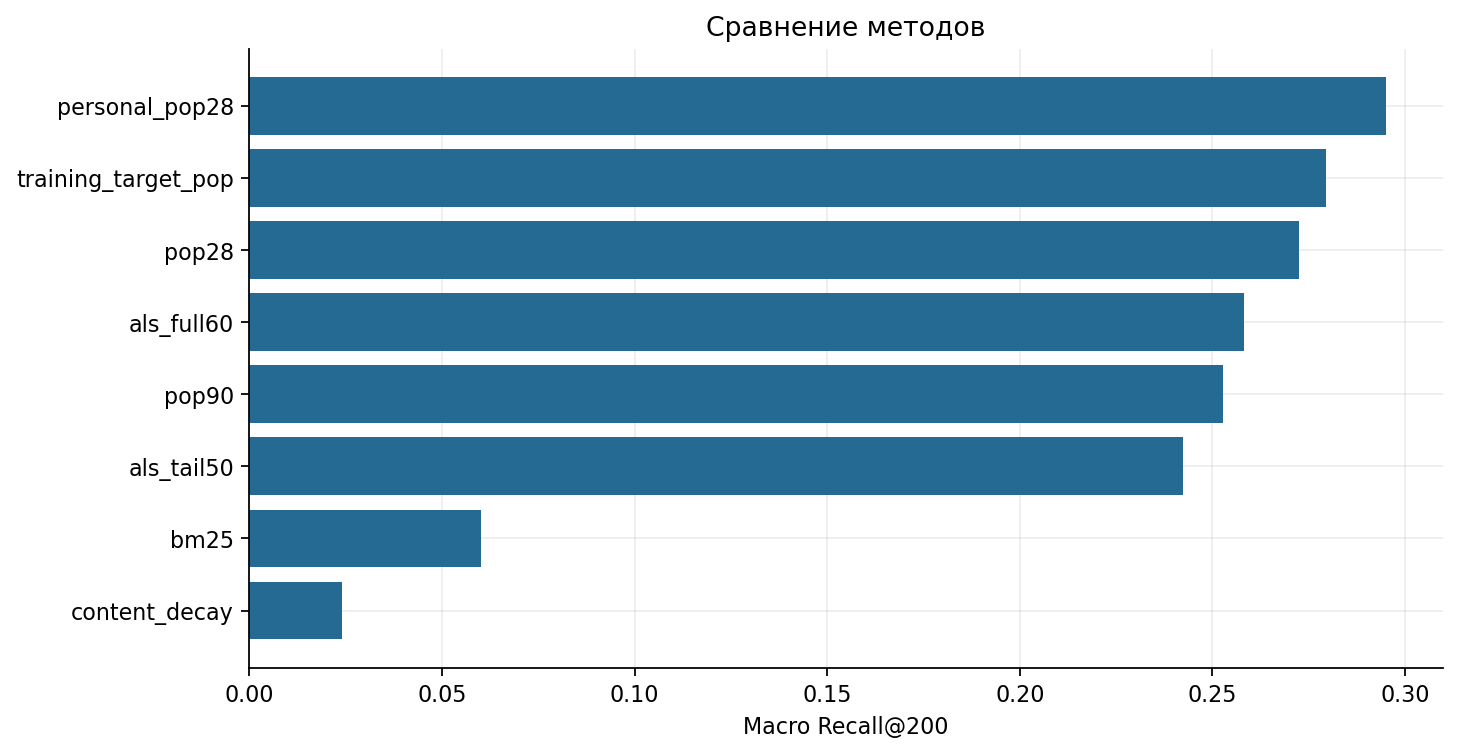

In [4]:
fig, ax = plt.subplots(figsize=(9,4.6))
d = classical.sort_values('recall_reachable@200')
ax.barh(d.method, d['recall_reachable@200'], color='#246A92')
ax.set(xlabel='Macro Recall@200', title='Сравнение методов')
save_figure(fig, figures/'classical.png')
plt.show()

## 3. Двухбашенная модель

Товарная башня: ID-вектор размерности 32, 300 признаков товара и индикатор их наличия. Пользовательская башня: взвешенная история с остаточной связью. Выход — 64 числа.

Обучение: 436 991 пара, 86 983 пользователя, batch 512, 256 негативов, температура 0,1, LR 0,0003, 8 проходов. Градиенты четырёх общих линейных слоёв считаются блоками. Checkpoint выбирается по Recall@200 без поправки на популярность. На выбранных весах сравниваются скалярное произведение и поправка logQ с коэффициентом 0,1.

In [5]:
study.run('two_tower')
tt = json.loads((study.results/'two_tower_selection.json').read_text())
variants = pd.DataFrame(tt['variants'])[['scoring', 'recall_reachable@200', 'ndcg@200', 'best_updates']]
display(variants.rename(columns={'scoring': 'Оценка', 'recall_reachable@200': 'Recall@200',
                                'ndcg@200': 'NDCG@200', 'best_updates': 'Выбранный шаг'}))
selected_score = {'raw': 'без поправки на популярность',
                  'same_fixed_prior': 'с фиксированной поправкой на популярность'}
print(f"Для объединений выбран вариант {selected_score[tt['selected']['scoring']]}.")

Этап «Двухбашенная модель» завершён.


,Оценка,Recall@200,NDCG@200,Выбранный шаг
0,raw,0.275566,0.086305,500
1,same_fixed_prior,0.281146,0.091971,500


Для объединений выбран вариант с фиксированной поправкой на популярность.


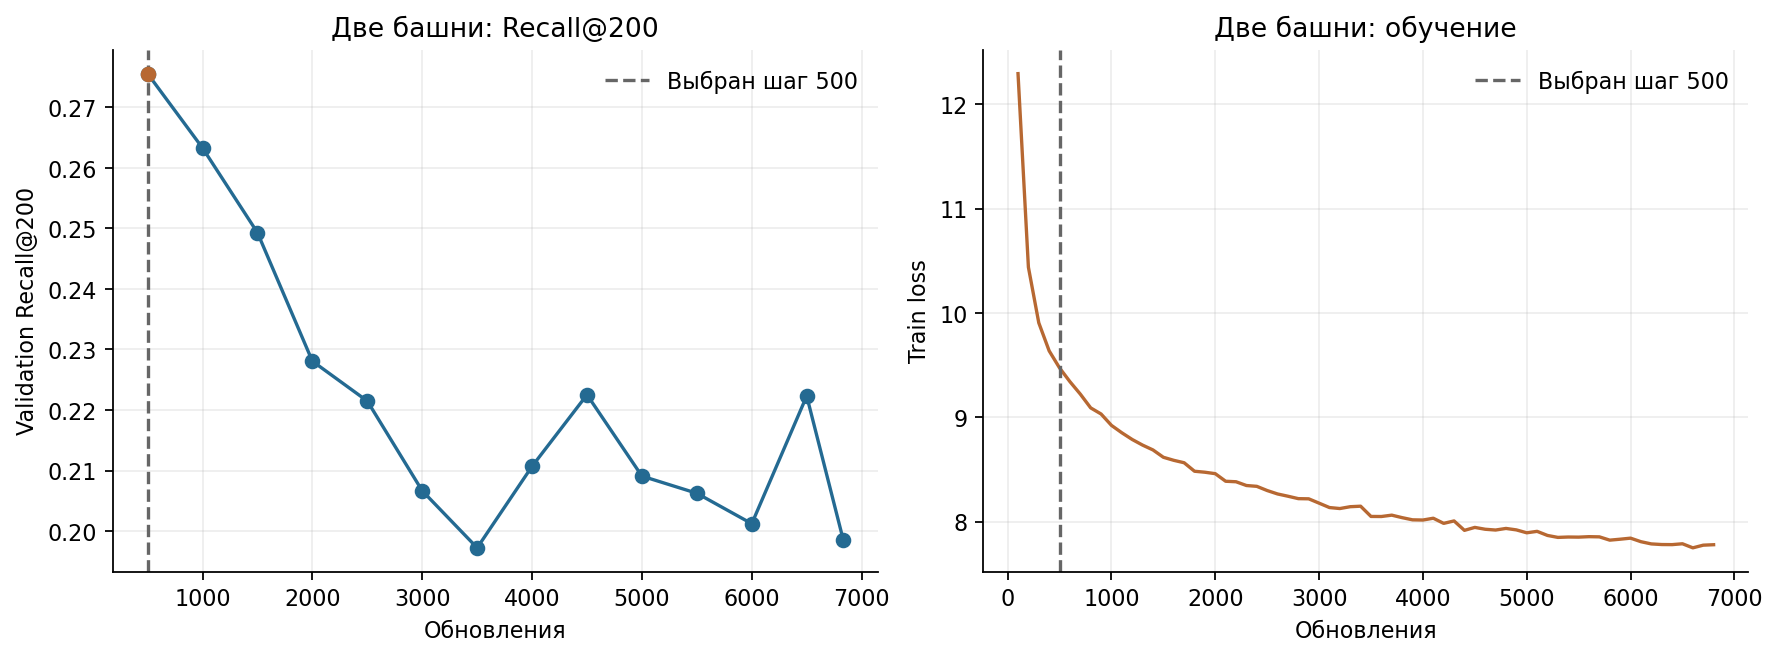

In [6]:
curve = study.table('two_tower_learning_curve.csv')
best_step = tt['selected']['best_updates']
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(curve.updates, curve.recall, 'o-', color='#246A92')
best = curve.loc[curve.updates.eq(best_step)].iloc[0]
axes[0].scatter(best.updates, best.recall, color='#B76832', zorder=3)
axes[0].set(xlabel='Обновления',ylabel='Validation Recall@200',title='Две башни: Recall@200')
loss_path = study.results/'two_tower_training_loss.csv'
if loss_path.exists():
    loss = pd.read_csv(loss_path)
    axes[1].plot(loss.updates,loss.mean_loss,color='#B76832')
axes[1].set(xlabel='Обновления',ylabel='Train loss',title='Две башни: обучение')
for ax in axes:
    ax.axvline(best_step, color='#666666', linestyle='--', label=f'Выбран шаг {best_step}')
    ax.legend(frameon=False)
save_figure(fig, figures/'two_tower_training.png')
plt.show()

## 4. Последовательная модель

Обучение: 334 094 примера, 53 696 пользователей. На входе — последние 50 событий, предшествующих целевому клику минимум на 24 часа. Один слой внимания, 2 головы, размерность 64, FFN 128, dropout 0,1.

256 негативов, температура 0,1, LR 0,001, 6000 обновлений. Для общих линейных слоёв используется блочный расчёт градиентов. Контроль с усреднением истории показан в главе 04; здесь он заново не обучается.

In [7]:
study.run('sequence')
seq = json.loads((study.results/'sequence_selection.json').read_text())
variants = pd.DataFrame(seq['variants'])[['scoring', 'recall_reachable@200', 'ndcg@200', 'best_updates']]
display(variants.rename(columns={'scoring': 'Оценка', 'recall_reachable@200': 'Recall@200',
                                'ndcg@200': 'NDCG@200', 'best_updates': 'Выбранный шаг'}))
selected_score = {'raw': 'без поправки на популярность',
                  'same_fixed_prior': 'с фиксированной поправкой на популярность'}
print(f"Для объединений выбран вариант {selected_score[seq['selected']['scoring']]}.")

Этап «Последовательная модель» завершён.


,Оценка,Recall@200,NDCG@200,Выбранный шаг
0,raw,0.254535,0.083558,2000
1,same_fixed_prior,0.271521,0.101161,2000


Для объединений выбран вариант с фиксированной поправкой на популярность.


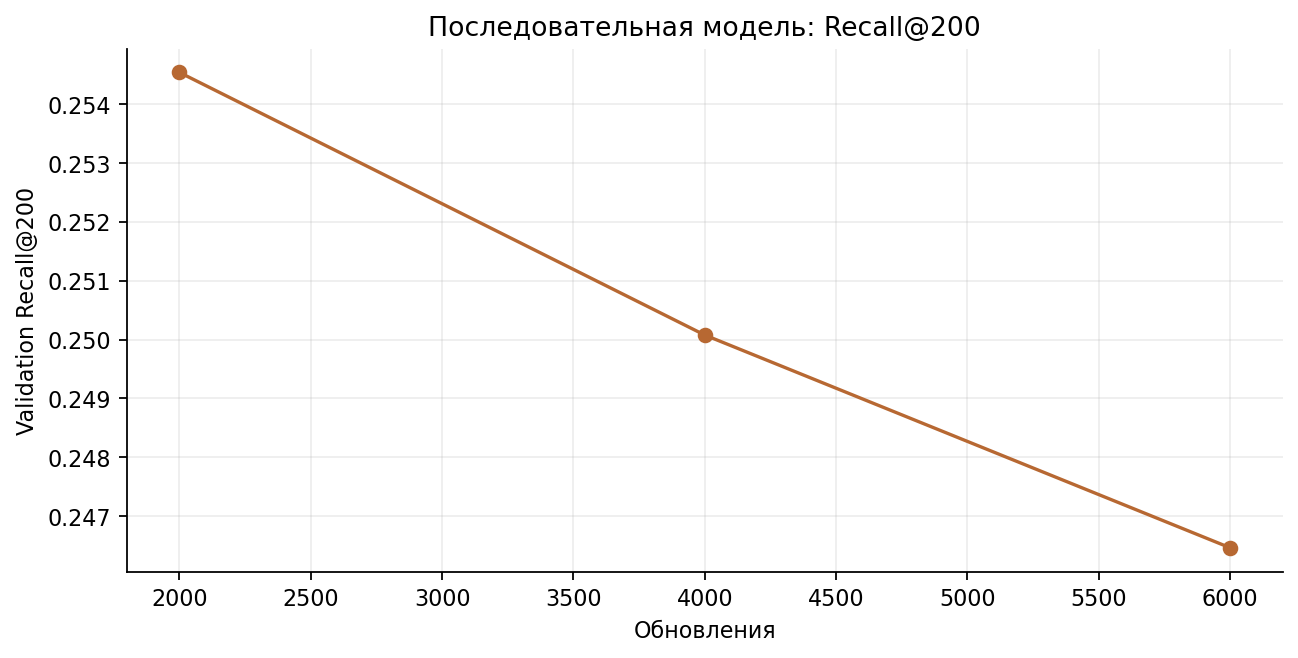

In [8]:
curve = study.table('sequence_learning_curve.csv')
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(curve.updates,curve.recall,'o-',color='#B76832')
ax.set(xlabel='Обновления',ylabel='Validation Recall@200',title='Последовательная модель: Recall@200')
save_figure(fig, figures/'sequence_training.png')
plt.show()

## 5. Сравнение и объединение выдач

Для каждой нейросети сохраняются результаты с поправкой logQ и без неё.
В объединения входит вариант с более высоким Recall@200 на периоде 1293–1299.
Квоты каналов заданы в конфигурации до запуска.

Отдельно проверяются объединения с личной частотой, все пять моделей вместе
и добавление глобальной популярности.

In [9]:
study.run('compare')
models = study.table('model_comparison.csv')
fusions = study.table('fusion_comparison.csv')
main_names = ['personal_pop28','bm25','content_decay','als_full60','two_tower','sequence']
main = models[models.method.isin(main_names)].sort_values('recall_reachable@200',ascending=False)
display(main[['method','recall_reachable@200','recall_all@200','ndcg@200','fit_seconds']])
display(fusions[['method','recall_reachable@200','ndcg@200','delta','low95','high95','added','lost']])

Этап «Сравнение выдач» завершён.


,method,recall_reachable@200,recall_all@200,ndcg@200,fit_seconds
2,personal_pop28,0.295046,0.284171,0.112669,0.000000
12,two_tower,0.281146,0.269152,0.091971,2019.918423
13,sequence,0.271521,0.260498,0.101161,895.493844
7,als_full60,0.258313,0.248909,0.081926,44.944467
4,bm25,0.060203,0.057675,0.021846,4.750619
5,content_decay,0.024058,0.023177,0.012698,0.000000


,method,recall_reachable@200,ndcg@200,delta,low95,high95,added,lost
0,personal_pop90_25,0.326071,0.113031,0.031025,0.026970,0.035379,439,86
1,personal_train_pop10,0.324211,0.131173,0.029165,0.025532,0.033266,383,30
2,personal_als10_tt10,0.320590,0.116983,0.025545,0.021826,0.029333,375,62
3,personal_all5,0.318208,0.114431,0.023163,0.018666,0.027883,488,229
4,personal_tt10,0.311279,0.105090,0.016233,0.013575,0.019110,233,24
5,personal_als10_seq10,0.308708,0.114856,0.013662,0.010830,0.016757,229,65
6,personal_als10,0.304881,0.106218,0.009836,0.007716,0.012329,143,24
7,personal_seq10,0.299685,0.114421,0.004639,0.002962,0.006532,84,25
8,all5_only,0.270139,0.087334,-0.024906,-0.031601,-0.017747,685,1079


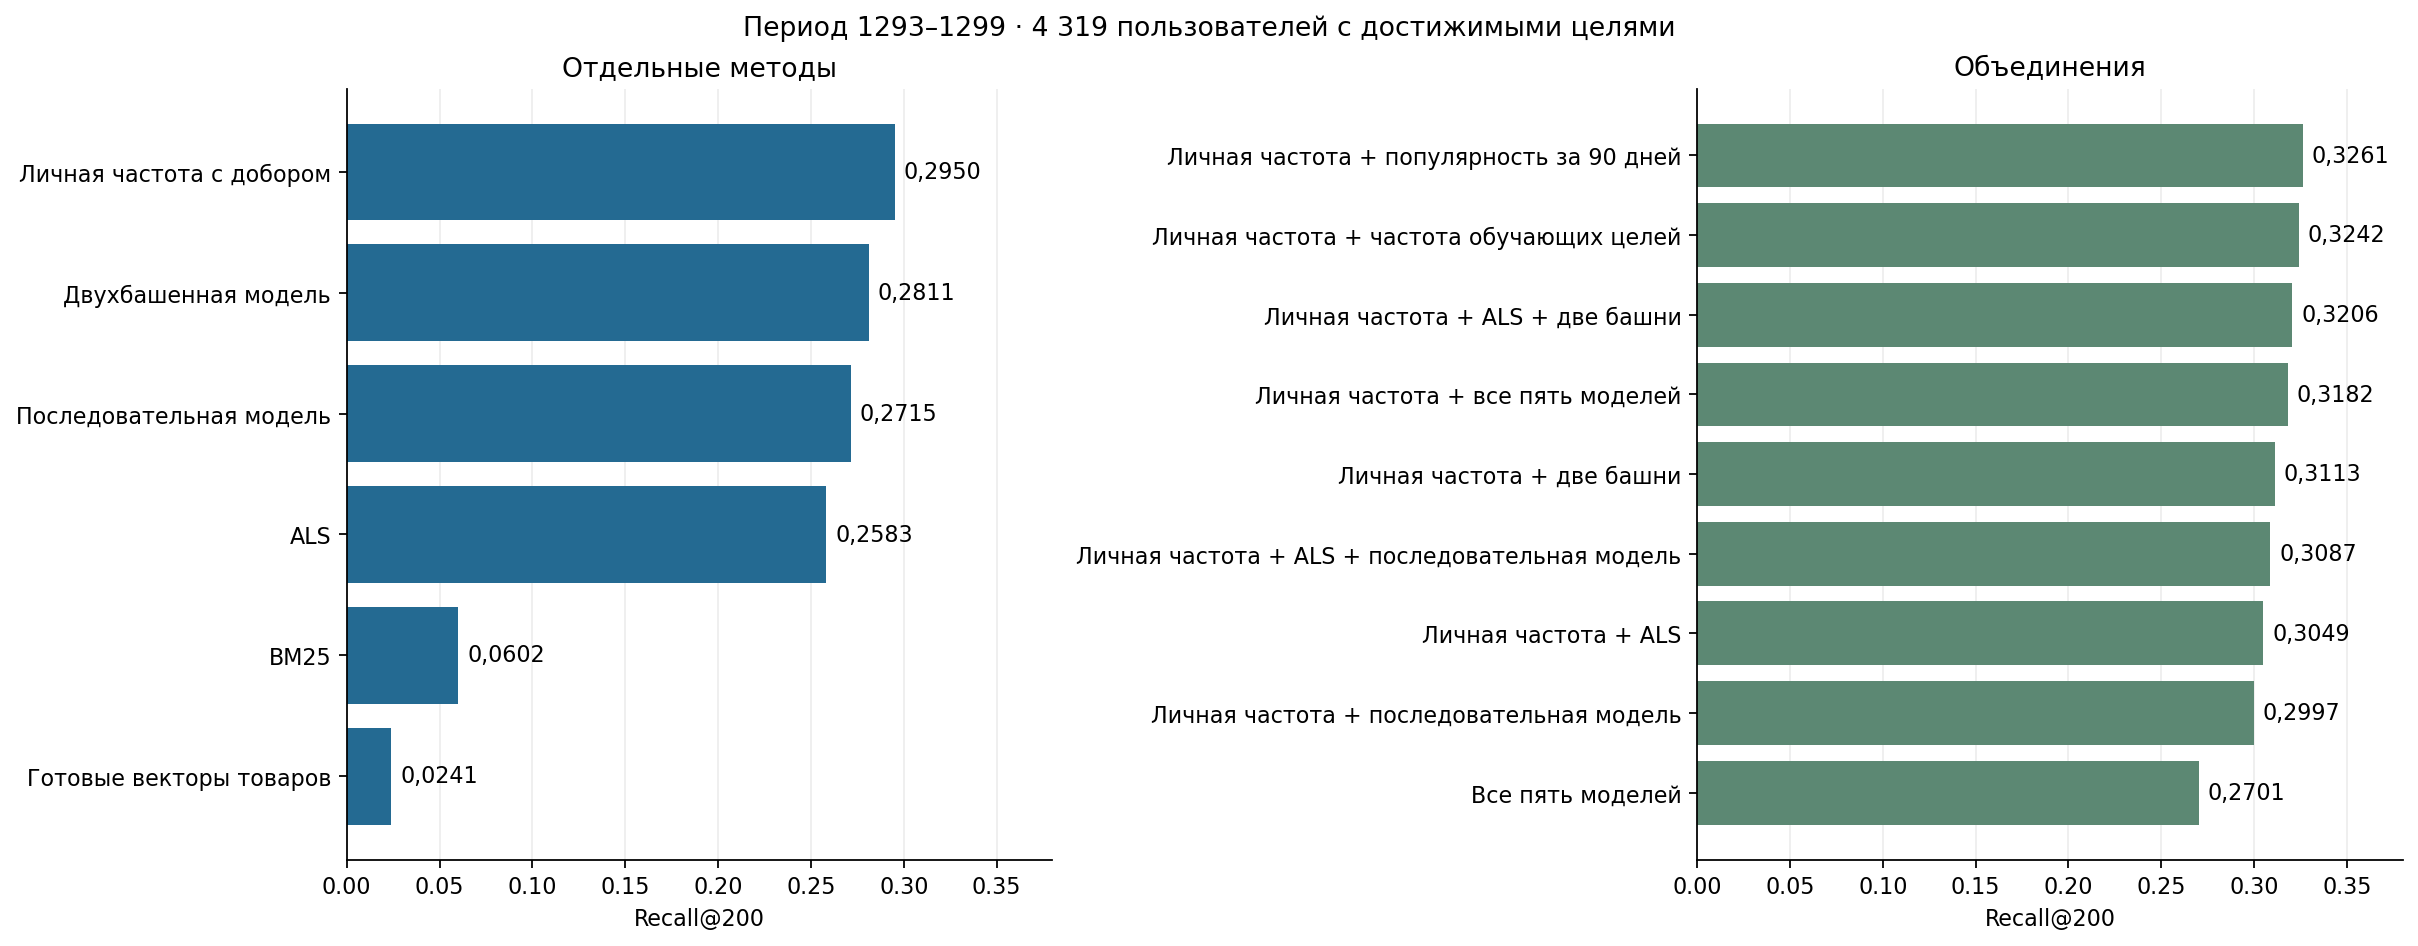

In [10]:
method_labels = {
    'personal_pop28': 'Личная частота с добором',
    'bm25': 'BM25',
    'content_decay': 'Готовые векторы товаров',
    'als_full60': 'ALS',
    'two_tower': 'Двухбашенная модель',
    'sequence': 'Последовательная модель',
}
fusion_labels = {
    'personal_als10': 'Личная частота + ALS',
    'personal_tt10': 'Личная частота + две башни',
    'personal_seq10': 'Личная частота + последовательная модель',
    'personal_als10_tt10': 'Личная частота + ALS + две башни',
    'personal_als10_seq10': 'Личная частота + ALS + последовательная модель',
    'personal_all5': 'Личная частота + все пять моделей',
    'all5_only': 'Все пять моделей',
    'personal_pop90_25': 'Личная частота + популярность за 90 дней',
    'personal_train_pop10': 'Личная частота + частота обучающих целей',
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharex=True)
metric = 'recall_reachable@200'
for ax, table, labels, title, color in (
    (axes[0], main, method_labels, 'Отдельные методы', '#246A92'),
    (axes[1], fusions, fusion_labels, 'Объединения', '#5C8873'),
):
    bars = ax.barh(table.method.map(labels), table[metric], color=color)
    ax.bar_label(bars, labels=[f'{value:.4f}'.replace('.', ',') for value in table[metric]], padding=4)
    ax.invert_yaxis()
    ax.set(xlabel='Recall@200', title=title, xlim=(0, 0.38))
    ax.grid(axis='y', visible=False)

period = f"{manifest['anchor']}–{manifest['target_end']}"
users = f"{manifest['reachable_users']:,}".replace(',', ' ')
fig.suptitle(f'Период {period} · {users} пользователей с достижимыми целями')
save_figure(fig, figures / 'models_and_fusions.png')
plt.show()

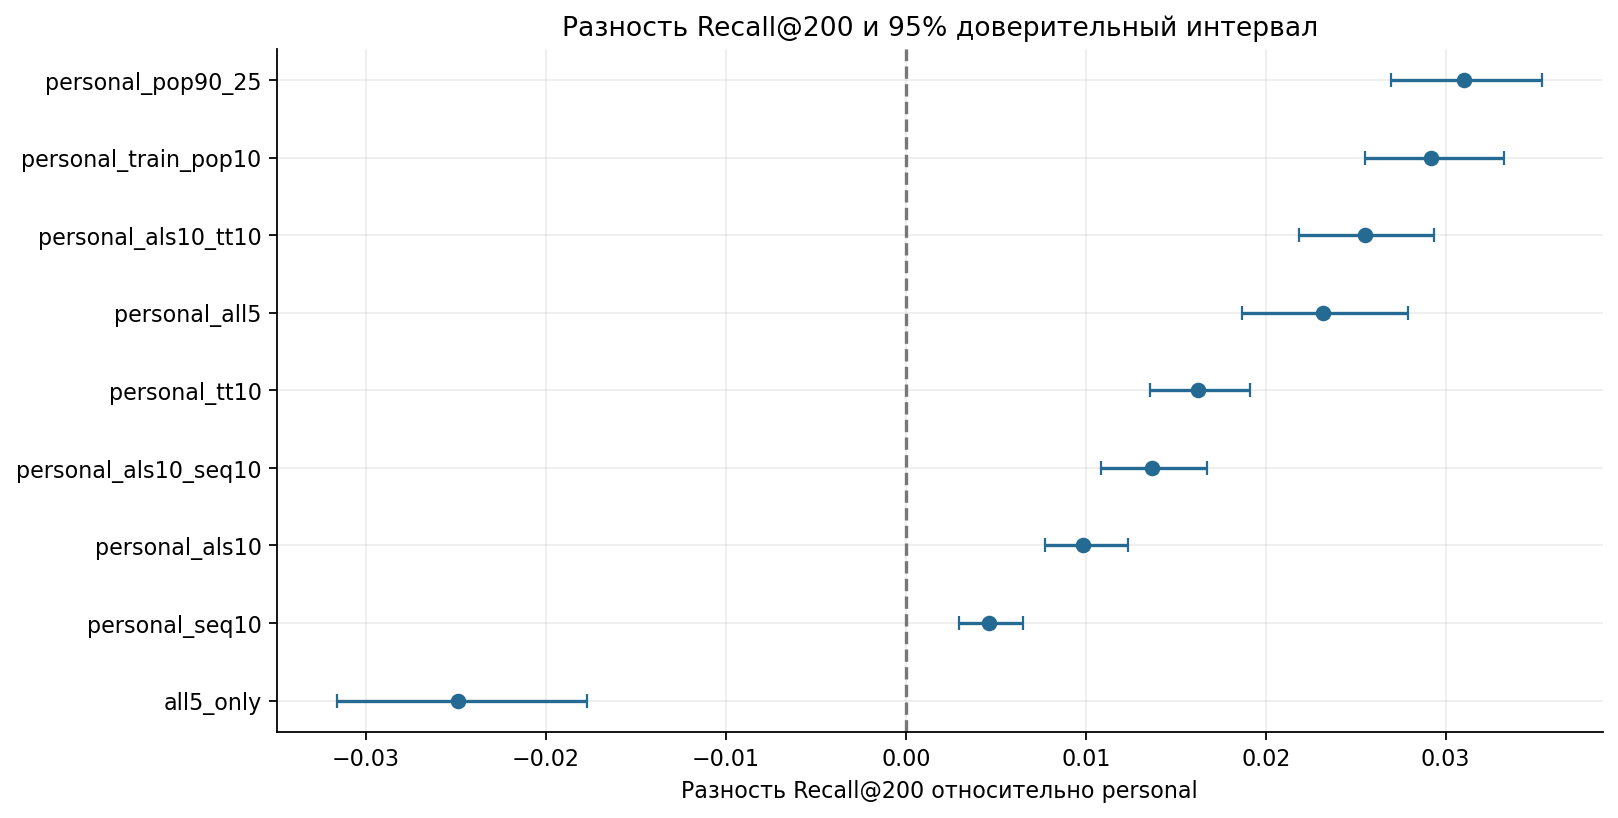

In [11]:
fig, ax = plt.subplots(figsize=(10,5))
d = fusions.sort_values('delta')
ax.errorbar(d.delta,np.arange(len(d)),xerr=np.vstack([d.delta-d.low95,d.high95-d.delta]),fmt='o',capsize=3,color='#246A92')
ax.axvline(0,color='#777777',ls='--')
ax.set(yticks=np.arange(len(d)),yticklabels=d.method,xlabel='Разность Recall@200 относительно personal',title='Разность Recall@200 и 95% доверительный интервал')
save_figure(fig, figures/'fusion_intervals.png')
plt.show()

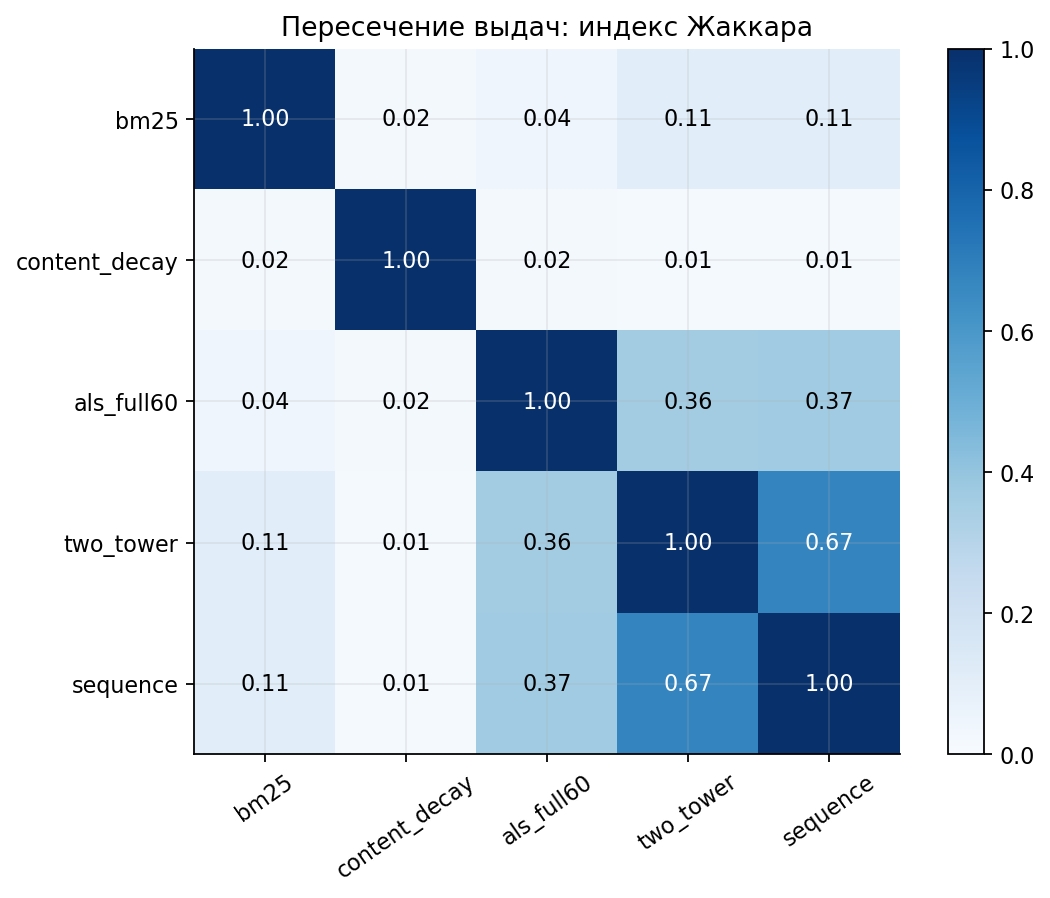

In [12]:
overlap = pd.read_csv(study.results/'ranking_overlap.csv',index_col=0)
fig, ax = plt.subplots(figsize=(7,5.5))
im = ax.imshow(overlap.to_numpy(),vmin=0,vmax=1,cmap='Blues')
ax.set(xticks=np.arange(len(overlap)),yticks=np.arange(len(overlap)),xticklabels=overlap.columns,yticklabels=overlap.index,title='Пересечение выдач: индекс Жаккара')
ax.tick_params(axis='x',rotation=35)
for i in range(len(overlap)):
    for j in range(len(overlap)):ax.text(j,i,f'{overlap.iloc[i,j]:.2f}',ha='center',va='center',color='white' if overlap.iloc[i,j]>.65 else 'black')
fig.colorbar(im,ax=ax)
save_figure(fig, figures/'overlap.png')
plt.show()

## 6. Результаты

Сравниваем отдельные методы и объединения по Recall@200. Для лучшего объединения показываем прирост относительно личной частоты и 95% доверительный интервал.

In [13]:
best_model = main.iloc[0]
best_fusion = fusions.iloc[0]
print(f"{method_labels[best_model['method']]} — Recall@200 {best_model['recall_reachable@200']:.6f}")
print(f"{fusion_labels[best_fusion['method']]} — Recall@200 {best_fusion['recall_reachable@200']:.6f}")
print(f"Прирост относительно личной частоты {best_fusion['delta']:+.6f} "
      f"(95% ДИ от {best_fusion['low95']:+.6f} до {best_fusion['high95']:+.6f})")
study.export(chapter)

Личная частота с добором — Recall@200 0.295046
Личная частота + популярность за 90 дней — Recall@200 0.326071
Прирост относительно личной частоты +0.031025 (95% ДИ от +0.026970 до +0.035379)
Таблицы и настройки сохранены в research/07_best_models/results.


## Вывод

Личная частота с популярностью за 90 дней дала наибольший Recall@200 на 1293–1299. Добавление всех пяти моделей дало 0,3182. У двух башен лучший шаг без поправки на популярность оказался 500. После восьми проходов Recall был ниже. [Сравнение недель и ограничения](README.md)